# Phần Hải (1/2) — K-Nearest Neighbors (K-NN) trên Luồng A và Luồng B

**K-Nearest Neighbors (K-NN)** là thuật toán phân loại dựa trên việc tìm kiếm $k$ mẫu dữ liệu huấn luyện
gần nhất với điểm dữ liệu cần dự đoán trong không gian đặc trưng và bỏ phiếu đa số.

**Các điểm cốt lõi khi áp dụng K-NN:**
- **Độ đo khoảng cách:** Sử dụng khoảng cách Euclidean hoặc Manhattan.
- **Chuẩn hóa dữ liệu (Quan trọng nhất):** Do K-NN dựa trên khoảng cách hình học, các đặc trưng có thang đo lớn
  (như `tenure` 0–72 tháng hay `MonthlyCharges` 18–118$) sẽ lấn át hoàn toàn các đặc trưng nhị phân nếu không được scale.
  - *Luồng A:* Đã được Mạnh chuẩn hóa sẵn bằng `StandardScaler`.
  - *Luồng B:* Bắt buộc kết hợp với `StandardScaler` trong `Pipeline` để scale độc lập trên từng fold train khi CV,
    ngăn ngừa triệt để rò rỉ thông tin (data leakage).
- **Quy trình:** Dùng `GridSearchCV` 5-fold Stratified CV trên tập Train, chọn tham số theo **F1-score của lớp Churn = Yes**,
  sau đó đánh giá mô hình tối ưu trên đúng tập Test chung của nhóm.

In [1]:
import sys
from pathlib import Path

# Tự động tìm thư mục gốc của dự án và thêm vào sys.path để import được module src
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").exists():
  PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
  sys.path.insert(0, str(PROJECT_ROOT))

# Các thư viện chuẩn
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Các module của dự án trong src/
from src.config import POSITIVE_LABEL, RANDOM_STATE, TARGET_COLUMN
from src.evaluate import danh_gia_mo_hinh
from src.train_knn import (
    doc_du_lieu,
    luu_ket_qua,
    tao_search,
    ve_confusion_matrix,
)

## 1. Huấn luyện và Tinh chỉnh siêu tham số trên tập Train

Ta tìm kiếm các giá trị tối ưu của:
- Số láng giềng $k \in [3, 5, 7, 9, 11, 15, 21, 31, 41, 51]$
- Trọng số láng giềng: `uniform` hoặc `distance`
- Hệ đo khoảng cách: `euclidean` hoặc `manhattan`

In [2]:
search, du_lieu = {}, {}

for luong in ["A", "B"]:
    X_train, X_test, y_train, y_test = doc_du_lieu(luong)
    du_lieu[luong] = (X_train, X_test, y_train, y_test)
    
    s = tao_search(luong)
    s.fit(X_train, y_train)
    search[luong] = s
    
    print(f"===== K-NN Luồng {luong} =====")
    print("Tham số tối ưu:", s.best_params_)
    print(f"F1 CV trên Train: {s.best_score_:.4f}\n")


===== K-NN Luồng A =====
Tham số tối ưu: {'metric': 'manhattan', 'n_neighbors': 41, 'weights': 'uniform'}
F1 CV trên Train: 0.6068

===== K-NN Luồng B =====
Tham số tối ưu: {'knn__metric': 'euclidean', 'knn__n_neighbors': 51, 'knn__weights': 'uniform'}
F1 CV trên Train: 0.5775



## 2. Đánh giá mô hình K-NN trên tập Test chung

In [3]:
du_doan = {}
bang = []

for luong in ["A", "B"]:
    _, X_test, _, y_test = du_lieu[luong]
    y_pred = search[luong].best_estimator_.predict(X_test)
    metrics = danh_gia_mo_hinh(y_test, y_pred, pos_label=POSITIVE_LABEL, in_chi_tiet=False)
    luu_ket_qua(luong, search[luong], metrics)
    du_doan[luong] = y_pred
    bang.append({
        "Luồng": luong,
        "Số đặc trưng": X_test.shape[1],
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1-score": metrics["f1_score"],
        "CV F1": search[luong].best_score_,
    })

pd.DataFrame(bang).set_index("Luồng")


Đã lưu kết quả: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\results\hai_knn_A.json
Đã lưu mô hình: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\models\knn_A.pkl
Đã lưu kết quả: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\results\hai_knn_B.json
Đã lưu mô hình: C:\Users\admin\Desktop\Subject\Nhap_Mon_Hoc_May\BTL\BTL_New_Version\BTL_Nhap_Mon_Hoc_May_NHOM4\models\knn_B.pkl


,Số đặc trưng,Accuracy,Precision,Recall,F1-score,CV F1
Luồng,,,,,,
A,45,0.786373,0.596817,0.601604,0.599201,0.606769
B,17,0.790632,0.623824,0.532086,0.574315,0.577516


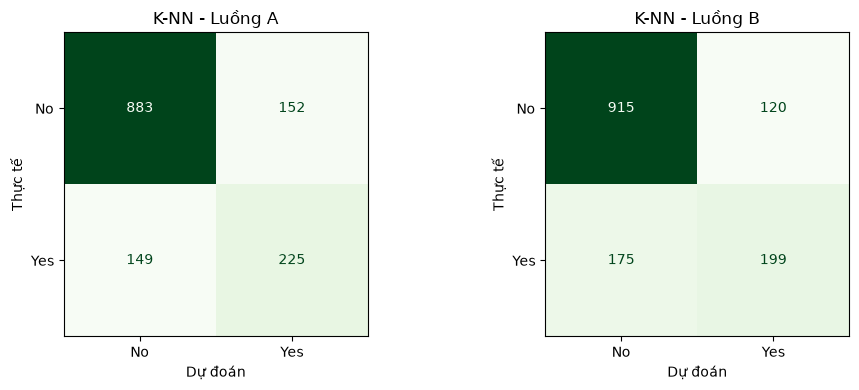

In [4]:
_, _, _, y_test = du_lieu["A"]
fig = ve_confusion_matrix(y_test, du_doan)
plt.show()


## 3. Nhận xét kết quả K-NN

1. **Ảnh hưởng của khoảng cách:** Trên Luồng A, khoảng cách Manhattan ($L_1$) cho kết quả vượt trội hơn Euclidean ($L_2$),
   đạt F1 $0.5992$ với $k=41$. Điều này hoàn toàn phù hợp với lý thuyết hình học: trong không gian nhiều chiều
   (45 đặc trưng gồm nhiều biến One-Hot nhị phân), khoảng cách Manhattan ít bị hiện tượng suy biến khoảng cách (Curse of Dimensionality) hơn Euclidean.
2. **So sánh với Decision Tree:** K-NN có độ chính xác tổng thể (Accuracy $\approx 0.79$) và Precision ($\approx 0.60 - 0.62$) cao hơn,
   tuy nhiên Recall lại thấp hơn đáng kể ($0.53 - 0.60$ so với $0.79 - 0.80$ của Decision Tree).
   Do bài toán Churn có phân bố mất cân bằng, việc bỏ phiếu đa số theo $k$ láng giềng khiến K-NN có xu hướng dự đoán theo lớp đa số ở các vùng ranh giới.